# 03 · Scenario and Stress Testing
Revalue every tranche under prepayment, spread and credit stresses and attribute P&L by sector.

In [1]:
import sys
import pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, '../scripts')
pd.set_option('display.width', 140)
portfolio = pd.read_csv('../data/sample_portfolio.csv', parse_dates=['maturity'])
from model import run_scenarios
from run_model import portfolio_summary, sector_pnl

In [2]:
results = run_scenarios(pd.read_csv('../data/sample_portfolio.csv'), pd.read_csv('../data/prepayment_rates.csv'))
portfolio_summary(results)

,scenario,market_value,pnl_vs_base,pnl_pct_of_notional,wavg_price,wavg_wal_yrs,wavg_eff_duration,wavg_cum_loss_pct
0,Base,2.343627e+09,0.0,0.00,94.99,5.05,3.93,1.36
1,Slow prepay (PSA_50),2.324400e+09,-19227071.0,-0.78,94.21,6.22,4.66,1.57
2,Fast prepay (PSA_200),2.370029e+09,26401358.0,1.07,96.06,3.60,2.97,1.07
3,Spreads +100bp,2.255317e+09,-88310580.0,-3.58,91.41,5.05,3.80,1.36
4,"Credit stress (3x CDR, +15% sev)",2.270540e+09,-73087132.0,-2.96,92.03,4.87,3.81,5.17
5,Combined stress,2.147106e+09,-196521257.0,-7.97,87.02,6.00,4.34,5.87


In [3]:
sector_pnl(results)

scenario,Base,Slow prepay (PSA_50),Fast prepay (PSA_200),Spreads +100bp,"Credit stress (3x CDR, +15% sev)",Combined stress
sector,,,,,,
Agency MBS,0.0,-1.14,1.39,-5.50,0.00,-7.93
ABS,0.0,-0.38,0.69,-1.68,-4.94,-7.31
CMBS,0.0,-0.08,0.15,-3.14,-3.37,-6.44
RMBS,0.0,-1.42,1.93,-4.67,-3.86,-10.63
CLO,0.0,-0.58,0.85,-2.20,-3.72,-7.16


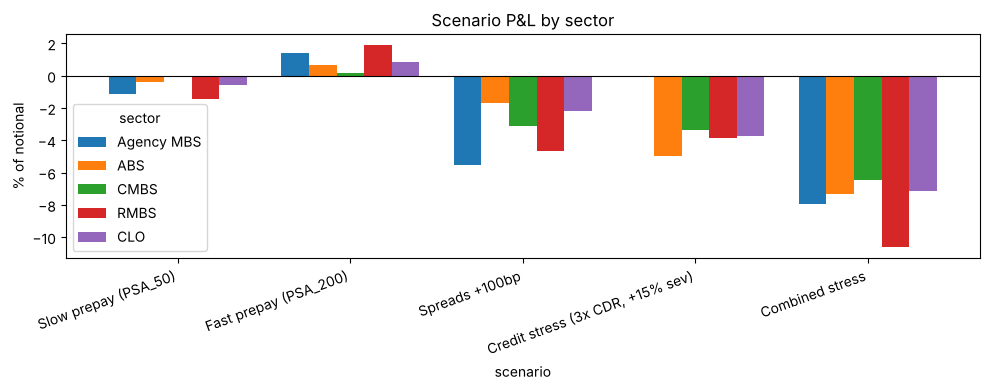

In [4]:
pct = sector_pnl(results).drop(columns='Base')
pct.T.plot.bar(figsize=(10, 4), width=0.8)
plt.axhline(0, color='black', lw=0.8); plt.ylabel('% of notional'); plt.title('Scenario P&L by sector')
plt.xticks(rotation=20, ha='right'); plt.tight_layout()

## Takeaways
- **Spread risk dominates for long-duration paper.** Agency MBS and RMBS lose the most when spreads widen 100bp because they have the longest durations.
- **Credit stress hits subordinate tranches and short consumer ABS.** Agency MBS are unaffected by design.
- **Prepayment direction matters.** With most bonds priced below par, faster prepayments are a gain and slower ones a loss, and slower prepayments also extend duration (extension risk).
- **The combined scenario is worse than either shock alone**, since slower prepayments leave more balance exposed to both higher defaults and wider spreads.

In [5]:
worst = results[results['scenario'] == 'Combined stress'].nsmallest(5, 'price_change')
worst[['id', 'sector', 'tranche', 'rating', 'price', 'price_change', 'cum_loss_pct']]

,id,sector,tranche,rating,price,price_change,cum_loss_pct
239,TRN1039,CLO,Junior,BB,70.983,-16.115,23.68
201,TRN1001,ABS,Junior,B,75.088,-14.591,21.40
214,TRN1014,RMBS,Mezzanine,BBB,71.751,-12.481,13.99
205,TRN1005,CMBS,Junior,BB,81.604,-12.146,17.01
236,TRN1036,RMBS,Mezzanine,BBB,71.162,-11.651,13.27
